# NB01 - Praproses dan Seleksi Citra Berdasarkan Confusion Line

Notebook ini menyiapkan seluruh kelas buah kecuali `000neg`, menghapus duplikat di dalam kelas, menyeragamkan ukuran citra, lalu mengukur kedekatan warna representatif pada area objek terhadap garis confusion protan dan deutan. Keputusan ambiguitas dibuat pada tingkat citra. Ringkasan per kelas memakai distribusi jarak, bukan hanya rata-rata.

Urutan: inventarisasi, deduplikasi, resize, segmentasi foreground otomatis, analisis confusion line per citra, filter citra dan kelas, undersampling per kelas untuk tiap tipe CVD, lalu penyeimbangan jumlah akhir antar keluarga CVD. Kuota akhir protan dan deutan sama dengan jumlah yang lebih kecil dari kedua keluarga; pemilihan tambahan hanya mengurangi keluarga yang lebih besar.

Folder hasil seleksi berbentuk `output/confusion_line_filtered/protan/apple_101.png` dan `output/confusion_line_filtered/deutan/apple_101.png`. Satu citra dapat masuk ke kedua folder jika memenuhi kriteria keduanya.


In [1]:
%pip install opencv-python-headless numpy pillow imagehash pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Konfigurasi


In [2]:
from __future__ import annotations

import json
import random
import re
import shutil
import sys
import time
from pathlib import Path

import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((candidate for candidate in CORE_CANDIDATES if (candidate / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/utils.py tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from utils import find_research_root, sha256_file, write_csv

RESEARCH_ROOT = find_research_root("datasets/raw/fruits")
RAW_DATASET_DIR = RESEARCH_ROOT / "datasets" / "raw" / "fruits"
OUTPUT_DIR = RESEARCH_ROOT / "notebooks" / "01" / "output"
PROCESSED_DIR = RESEARCH_ROOT / "datasets" / "processed"
CONFUSION_OUTPUT_DIR = OUTPUT_DIR / "confusion_line_filtered"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SUBSET = "train"
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
PHASH_THRESHOLD = 4
OUTPUT_SIZE = 512
SEGMENTATION_SIZE = 128
GRABCUT_BORDER_FRACTION = 0.03
COLOR_SAMPLES_PER_IMAGE = 1000
KMEANS_CLUSTERS = 4
RANDOM_SEED = 42

# Copunctal points in CIE 1931 xy, reported in Tsekouras et al. (2021), Figure 1.
COPUNCTAL_POINTS = {
    "protan": (0.763, 0.236),
    "deutan": (1.4, -0.4),
}

ALL_RAW_CLASSES = sorted(
    directory.name for directory in RAW_DATASET_DIR.iterdir()
    if directory.is_dir() and directory.name != "000neg" and (directory / SUBSET).exists()
)
if not ALL_RAW_CLASSES:
    raise RuntimeError("Tidak ditemukan kelas buah selain 000neg.")
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print(f"Kelas buah yang diproses: {len(ALL_RAW_CLASSES)}")


Kelas buah yang diproses: 19


## Tahap 2 - Inventarisasi Seluruh Kelas Buah


In [3]:
def list_images(directory: Path) -> list[Path]:
    return sorted(
        path for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
    )

inventory_rows = []
for source_class in ALL_RAW_CLASSES:
    class_dir = RAW_DATASET_DIR / source_class / SUBSET
    images = list_images(class_dir)
    inventory_rows.append({
        "source_class": source_class,
        "subset": SUBSET,
        "raw_image_count": len(images),
        "source_directory": str(class_dir),
    })
inventory = pd.DataFrame(inventory_rows)
if inventory.empty or (inventory["raw_image_count"] == 0).any():
    raise RuntimeError("Ada kelas buah tanpa citra pada subset yang dipilih.")
print(inventory.to_string(index=False))
print(f"Total kelas: {len(inventory)}")
print(f"Total citra raw tanpa 000neg: {int(inventory['raw_image_count'].sum())}")


  source_class subset  raw_image_count                                                           source_directory
      001apple  train              418       C:\colorblind_simulation\research\datasets\raw\fruits\001apple\train
     002orange  train              432      C:\colorblind_simulation\research\datasets\raw\fruits\002orange\train
       003pear  train              268        C:\colorblind_simulation\research\datasets\raw\fruits\003pear\train
     004tomato  train              411      C:\colorblind_simulation\research\datasets\raw\fruits\004tomato\train
 005strawberry  train              450  C:\colorblind_simulation\research\datasets\raw\fruits\005strawberry\train
     006banana  train              394      C:\colorblind_simulation\research\datasets\raw\fruits\006banana\train
 007watermelon  train              239  C:\colorblind_simulation\research\datasets\raw\fruits\007watermelon\train
       008kiwi  train              311        C:\colorblind_simulation\research\datasets

## Tahap 3 - Deduplikasi dan Resize

Deduplikasi pHash dilakukan per kelas sebelum pengukuran warna agar citra berulang tidak memperbesar bobot distribusi. Citra unik lalu dipotong persegi dari tengah dan diubah ke ukuran seragam, mengikuti tahapan praproses yang sudah ada. Semua kelas buah selain `000neg` diproses; belum ada kelas yang dikeluarkan berdasarkan nama atau hue.


In [4]:
def compute_phash(image_path: Path) -> imagehash.ImageHash:
    with Image.open(image_path) as image:
        return imagehash.phash(image)


def deduplicate_images(
    image_paths: list[Path],
    threshold: int = PHASH_THRESHOLD,
) -> tuple[list[Path], list[tuple[Path, Path, int]]]:
    kept: list[Path] = []
    kept_hashes: list[imagehash.ImageHash] = []
    duplicates: list[tuple[Path, Path, int]] = []
    for path in image_paths:
        current_hash = compute_phash(path)
        match = next(
            ((existing_path, existing_hash) for existing_path, existing_hash in zip(kept, kept_hashes)
             if current_hash - existing_hash <= threshold),
            None,
        )
        if match is None:
            kept.append(path)
            kept_hashes.append(current_hash)
        else:
            existing_path, existing_hash = match
            duplicates.append((path, existing_path, current_hash - existing_hash))
    return kept, duplicates


def center_crop_resize(source_path: Path, destination_path: Path, size: int = OUTPUT_SIZE) -> None:
    image = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("Citra tidak dapat dibaca oleh OpenCV")
    height, width = image.shape[:2]
    edge = min(height, width)
    top, left = (height - edge) // 2, (width - edge) // 2
    cropped = image[top:top + edge, left:left + edge]
    resized = cv2.resize(cropped, (size, size), interpolation=cv2.INTER_AREA)
    destination_path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(destination_path), resized):
        raise IOError("Citra hasil tidak dapat ditulis")


prepared_rows: list[dict] = []
duplicate_records: list[dict] = []
error_rows: list[dict] = []
for source_class in ALL_RAW_CLASSES:
    source_images = list_images(RAW_DATASET_DIR / source_class / SUBSET)
    try:
        unique_images, duplicates = deduplicate_images(source_images)
    except Exception as error:
        error_rows.append({"stage": "deduplication", "source_class": source_class, "source_path": "", "error": str(error)})
        continue
    for duplicate_path, kept_path, distance in duplicates:
        duplicate_records.append({
            "source_class": source_class,
            "duplicate_file": duplicate_path.name,
            "kept_file": kept_path.name,
            "hamming_distance": int(distance),
        })
    for source_path in unique_images:
        output_path = PROCESSED_DIR / source_class / f"{source_path.stem}.png"
        try:
            started = time.perf_counter()
            center_crop_resize(source_path, output_path)
            prepared_rows.append({
                "subset": SUBSET,
                "source_class": source_class,
                "source_file_name": source_path.name,
                "source_path": str(source_path),
                "output_file_name": output_path.name,
                "output_path": str(output_path),
                "output_sha256": sha256_file(output_path),
                "processing_seconds": round(time.perf_counter() - started, 6),
            })
        except Exception as error:
            error_rows.append({"stage": "preprocessing", "source_class": source_class, "source_path": str(source_path), "error": str(error)})

prepared_manifest = pd.DataFrame(prepared_rows)
if prepared_manifest.empty:
    raise RuntimeError("Tidak ada citra yang berhasil dideduplikasi dan di-resize.")
prepared_manifest = prepared_manifest.sort_values(["source_class", "source_file_name"]).reset_index(drop=True)
print(f"Citra unik yang berhasil di-resize: {len(prepared_manifest)}")
print(f"Duplikat yang dihapus: {len(duplicate_records)}")


Citra unik yang berhasil di-resize: 4692
Duplikat yang dihapus: 178


## Tahap 4 - Analisis Confusion Line pada Area Objek per Citra

Metode citra utama mengikuti Tsekouras et al. (2021), yang mengekstrak warna representatif dari citra, memetakannya ke diagram kromatisitas CIE 1931, dan menguji kedekatannya pada confusion line. Studi tersebut juga menguji metode citranya pada koleksi McGill *Flowers and Fruits*, termasuk 52 citra buah. Persamaan jarak titik-ke-garis yang dipakai di sini adalah Persamaan 12 pada artikel itu:

\[
d(v,L)=\frac{|(x_{cp}-x_0)(y_0-v_y)-(x_0-v_x)(y_{cp}-y_0)|}{\sqrt{(x_{cp}-x_0)^2+(y_{cp}-y_0)^2}}
\]

`(x_cp, y_cp)` adalah copunctal point, `(x_0, y_0)` adalah warna pusat cluster yang membentuk garis, dan `(v_x, v_y)` adalah pusat cluster warna pembanding. Jarak dihitung dua arah untuk setiap pasangan pusat cluster; setiap nilai tetap memakai Persamaan 12. Median dan kuartil dari jarak pasangan menjadi ringkasan per citra. Jarak kecil berarti dua pusat warna lebih dekat pada confusion line yang sama menurut geometri yang dipakai, bukan ambang diagnosis klinis.

Foreground diperoleh otomatis dengan GrabCut yang diinisialisasi dari kotak tengah citra, lalu pusat warna diekstrak dengan K-means. Inisialisasi kotak tengah adalah adaptasi operasional untuk dataset buah yang objeknya terpusat, bukan persamaan dari artikel confusion line. Overlay mask disediakan untuk audit kualitas segmentasi. K-means `K=4` mengikuti preseden segmentasi citra buah Pham dan Lee (2015).

Sumber: [Tsekouras et al. (2021), *A Novel Approach to Image Recoloring for Color Vision Deficiency*, Sensors 21(8), 2740, Bagian 3 dan Persamaan 12](https://doi.org/10.3390/s21082740); [Pham dan Lee (2015), segmentasi citra buah](https://doi.org/10.1007/s40595-014-0028-3). Penggunaan garis confusion sebagai ukuran persepsi didukung oleh [studi validasi tes warna digital (2024)](https://www.mdpi.com/2075-4418/14/4/396). Tanpa peserta CVD, keluaran NB01 adalah kesesuaian geometris dengan model confusion line, bukan bukti langsung tentang persepsi semua penderita.


In [5]:
def srgb_to_linear(rgb: np.ndarray) -> np.ndarray:
    """Apply the IEC 61966-2-1 sRGB decoding transfer function."""
    values = np.clip(np.asarray(rgb, dtype=np.float64), 0.0, 1.0)
    return np.where(values <= 0.04045, values / 12.92, ((values + 0.055) / 1.055) ** 2.4)


def rgb_to_cie_xy(rgb: np.ndarray) -> np.ndarray:
    """Convert sRGB colors to CIE 1931 xy chromaticity under the sRGB D65 matrix."""
    linear = srgb_to_linear(rgb)
    matrix = np.array([
        [0.4124564, 0.3575761, 0.1804375],
        [0.2126729, 0.7151522, 0.0721750],
        [0.0193339, 0.1191920, 0.9503041],
    ])
    xyz = linear @ matrix.T
    totals = xyz.sum(axis=1)
    valid = totals > np.finfo(np.float64).eps
    xy = np.full((len(xyz), 2), np.nan, dtype=np.float64)
    xy[valid] = xyz[valid, :2] / totals[valid, None]
    return xy


def point_to_confusion_line_distance(
    point: np.ndarray,
    line_point: np.ndarray,
    copunctal_point: tuple[float, float],
) -> float:
    """Equation 12, Tsekouras et al. (2021), for point-to-line distance."""
    x_cp, y_cp = copunctal_point
    x_0, y_0 = line_point
    v_x, v_y = point
    numerator = abs((x_cp - x_0) * (y_0 - v_y) - (x_0 - v_x) * (y_cp - y_0))
    denominator = np.sqrt((x_cp - x_0) ** 2 + (y_cp - y_0) ** 2)
    return float(numerator / denominator) if denominator > 0 else np.nan


def grabcut_object_pixels(image_bgr: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    small = cv2.resize(image_bgr, (SEGMENTATION_SIZE, SEGMENTATION_SIZE), interpolation=cv2.INTER_AREA)
    height, width = small.shape[:2]
    margin = max(1, round(min(width, height) * GRABCUT_BORDER_FRACTION))
    rect = (margin, margin, width - 2 * margin, height - 2 * margin)
    mask = np.zeros((height, width), dtype=np.uint8)
    background_model = np.zeros((1, 65), dtype=np.float64)
    foreground_model = np.zeros((1, 65), dtype=np.float64)
    cv2.grabCut(small, mask, rect, background_model, foreground_model, 3, cv2.GC_INIT_WITH_RECT)
    foreground = np.isin(mask, (cv2.GC_FGD, cv2.GC_PR_FGD))
    return small, foreground


def analyze_image_confusion(image_path: str, rng: np.random.Generator) -> dict:
    image_bgr = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise ValueError("Citra hasil resize tidak dapat dibaca")
    small_bgr, foreground_mask = grabcut_object_pixels(image_bgr)
    foreground_bgr = small_bgr[foreground_mask]
    if len(foreground_bgr) < KMEANS_CLUSTERS:
        raise ValueError("GrabCut menghasilkan piksel foreground yang tidak cukup untuk K-means")
    sample_count = min(COLOR_SAMPLES_PER_IMAGE, len(foreground_bgr))
    sample_indices = rng.choice(len(foreground_bgr), size=sample_count, replace=False)
    sample_rgb = foreground_bgr[sample_indices, ::-1].astype(np.float32) / 255.0
    cv2.setRNGSeed(RANDOM_SEED)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.2)
    _, labels, centers = cv2.kmeans(
        sample_rgb.reshape(-1, 3),
        KMEANS_CLUSTERS,
        None,
        criteria,
        3,
        cv2.KMEANS_PP_CENTERS,
    )
    center_xy = rgb_to_cie_xy(centers)
    if not np.isfinite(center_xy).all():
        raise ValueError("Pusat warna tidak dapat dipetakan ke CIE xy")

    result = {
        "foreground_fraction": float(foreground_mask.mean()),
        "key_color_count": int(len(center_xy)),
    }
    for cvd, copunctal_point in COPUNCTAL_POINTS.items():
        distances = []
        for first in range(len(center_xy)):
            for second in range(first + 1, len(center_xy)):
                distances.append(point_to_confusion_line_distance(center_xy[second], center_xy[first], copunctal_point))
                distances.append(point_to_confusion_line_distance(center_xy[first], center_xy[second], copunctal_point))
        distances = np.asarray(distances, dtype=np.float64)
        distances = distances[np.isfinite(distances)]
        if distances.size == 0:
            raise ValueError(f"Tidak ada jarak pasangan warna valid untuk {cvd}")
        result.update({
            f"{cvd}_pair_distance_mean": float(np.mean(distances)),
            f"{cvd}_pair_distance_median": float(np.median(distances)),
            f"{cvd}_pair_distance_q25": float(np.quantile(distances, 0.25)),
            f"{cvd}_pair_distance_q75": float(np.quantile(distances, 0.75)),
        })
    result["foreground_mask"] = foreground_mask
    return result


rng = np.random.default_rng(RANDOM_SEED)
image_records = []
mask_preview_records = []
for row in prepared_manifest.itertuples(index=False):
    try:
        metrics = analyze_image_confusion(row.output_path, rng)
        foreground_mask = metrics.pop("foreground_mask")
        image_records.append({
            "subset": row.subset,
            "source_class": row.source_class,
            "source_file_name": row.source_file_name,
            "source_path": row.source_path,
            "output_file_name": row.output_file_name,
            "output_path": row.output_path,
            "output_sha256": row.output_sha256,
            **metrics,
            "analysis_status": "ok",
            "analysis_error": "",
        })
        if len(mask_preview_records) < 6:
            preview_image = cv2.imread(row.output_path, cv2.IMREAD_COLOR)
            preview_mask = cv2.resize(
                foreground_mask.astype(np.uint8),
                (OUTPUT_SIZE, OUTPUT_SIZE),
                interpolation=cv2.INTER_NEAREST,
            ).astype(bool)
            mask_preview_records.append((row.source_class, preview_image, preview_mask))
    except Exception as error:
        image_records.append({
            "subset": row.subset,
            "source_class": row.source_class,
            "source_file_name": row.source_file_name,
            "source_path": row.source_path,
            "output_file_name": row.output_file_name,
            "output_path": row.output_path,
            "output_sha256": row.output_sha256,
            "analysis_status": "error",
            "analysis_error": str(error),
        })

image_analysis = pd.DataFrame(image_records)
valid_analysis = image_analysis[image_analysis["analysis_status"] == "ok"].copy()
if valid_analysis.empty:
    raise RuntimeError("Tidak ada citra yang berhasil dianalisis dengan confusion line.")
class_summary_rows = []
for source_class, group in valid_analysis.groupby("source_class"):
    summary = {"source_class": source_class, "image_count": len(group)}
    for cvd in COPUNCTAL_POINTS:
        metric = f"{cvd}_pair_distance_median"
        summary.update({
            f"{cvd}_distance_mean_across_images": float(group[metric].mean()),
            f"{cvd}_distance_median_across_images": float(group[metric].median()),
            f"{cvd}_distance_q25_across_images": float(group[metric].quantile(0.25)),
            f"{cvd}_distance_q75_across_images": float(group[metric].quantile(0.75)),
        })
    class_summary_rows.append(summary)
class_confusion_summary = pd.DataFrame(class_summary_rows)
if class_confusion_summary.empty:
    raise RuntimeError("Tidak ada ringkasan kelas yang dapat dihitung.")
print(f"Citra dianalisis: {len(valid_analysis)} dari {len(prepared_manifest)}")
print(f"Citra gagal analisis: {len(image_analysis) - len(valid_analysis)}")


Citra dianalisis: 4656 dari 4692
Citra gagal analisis: 36


### Audit Visual Mask dan Distribusi per Kelas

Tampilan mask membantu memeriksa apakah GrabCut menangkap objek dan tidak terlalu banyak memasukkan latar. Jika hasil mask sistematis keliru untuk suatu kelompok citra, jarak warna kelompok itu belum layak ditafsirkan sebagai warna objek. Statistik kelas menampilkan mean, median, kuartil 25 dan 75 agar variasi antarcitra terlihat.


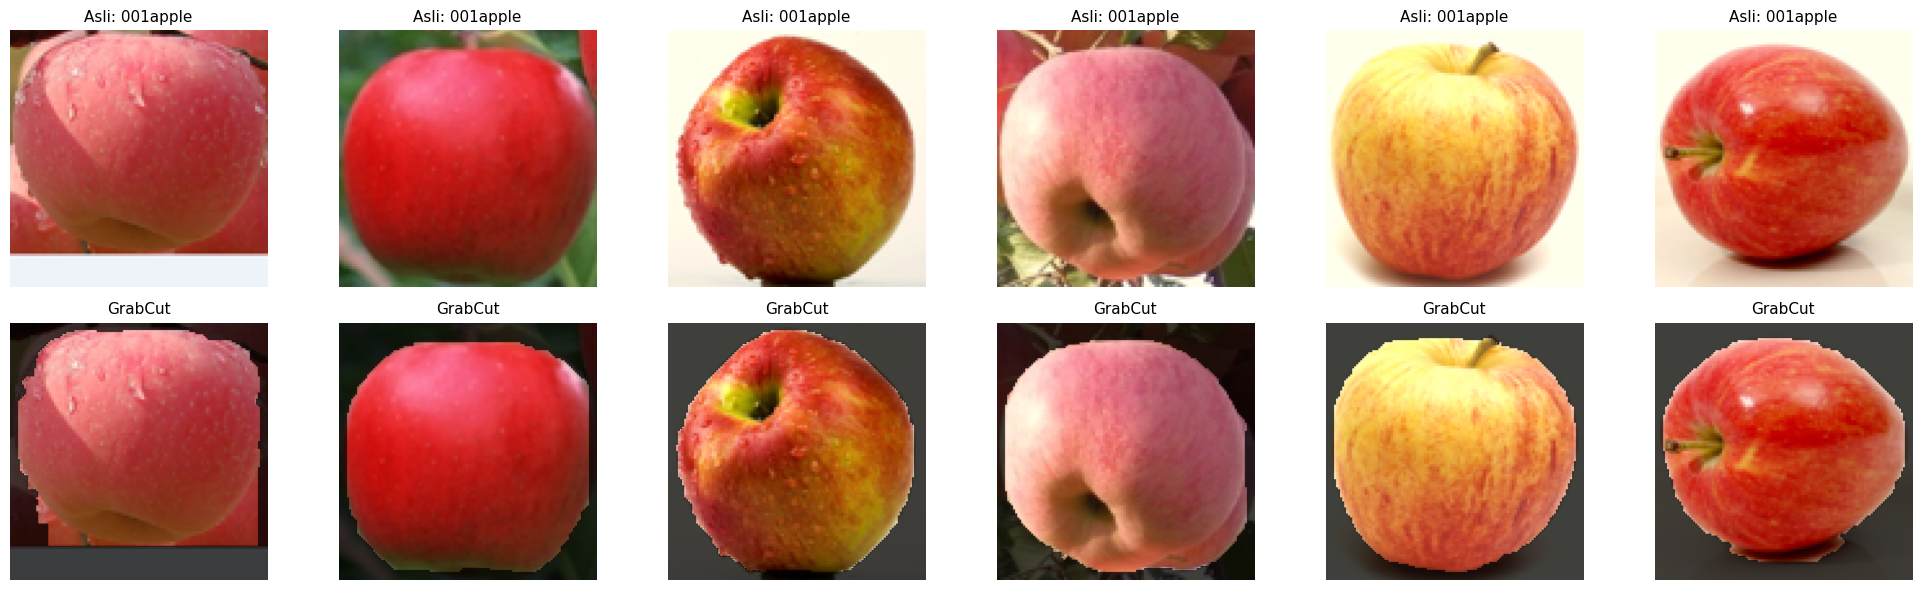

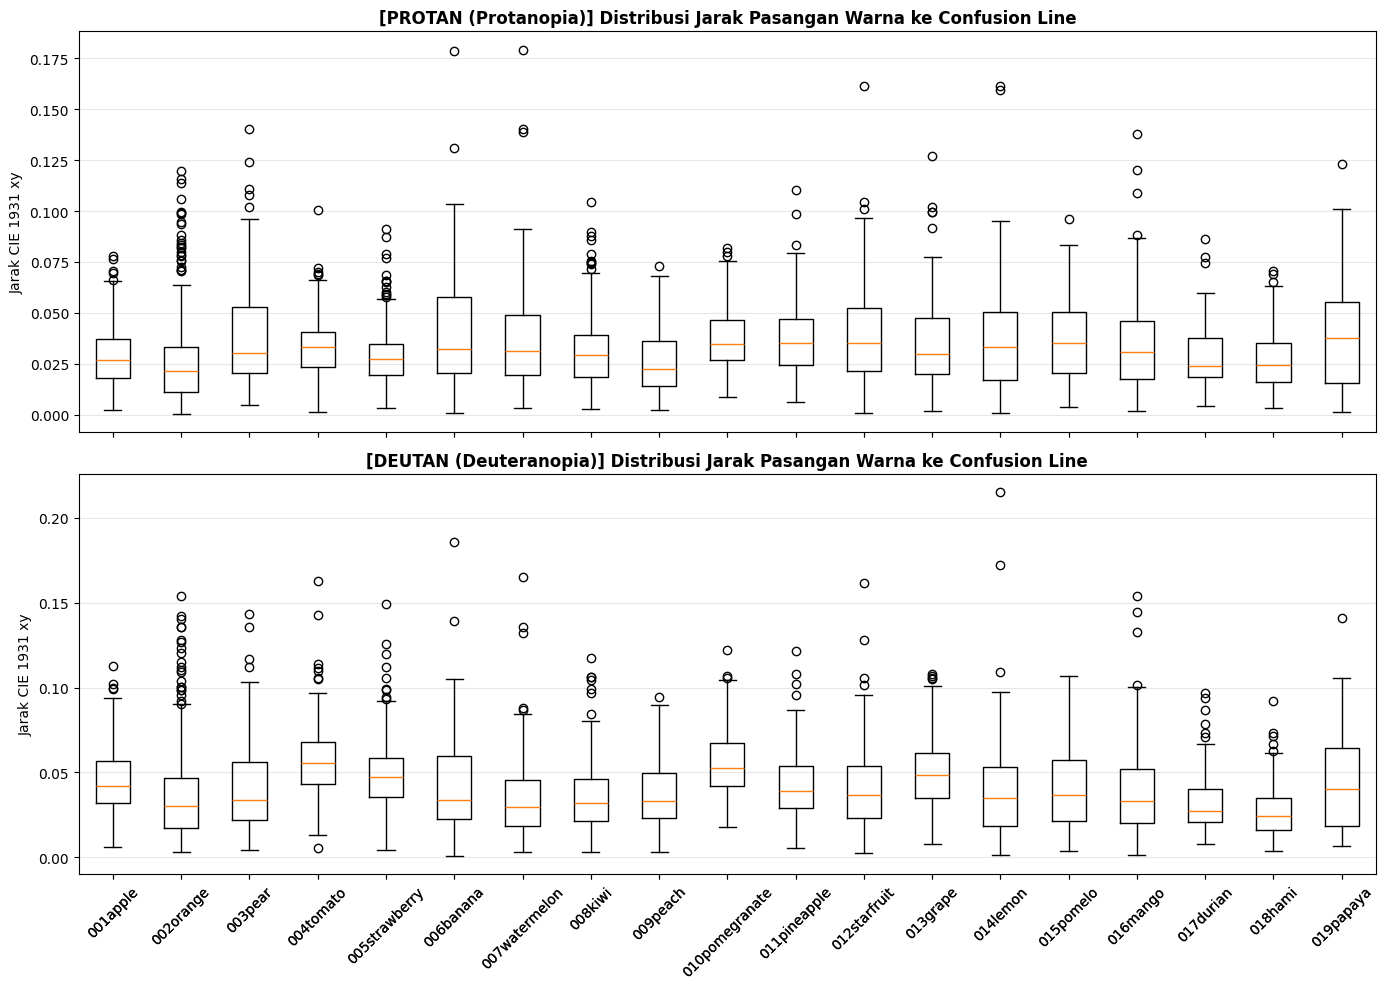

=== RINGKASAN CONFUSION LINE PER TIPE CVD (FORMAT BARIS) ===

 PROTAN (Protanopia)


,Kelas,image_count,distance_mean_across_images,distance_median_across_images,distance_q25_across_images,distance_q75_across_images
0,001apple,397,0.028275,0.026821,0.017959,0.037228
1,002orange,422,0.025954,0.021432,0.010885,0.033327
2,003pear,263,0.038574,0.030453,0.020516,0.052653
3,004tomato,403,0.032870,0.033241,0.023216,0.040770
4,005strawberry,438,0.028420,0.027410,0.019699,0.034765
5,006banana,372,0.039807,0.032158,0.020506,0.057764
6,007watermelon,223,0.036887,0.031414,0.019296,0.048919
7,008kiwi,300,0.031079,0.029232,0.018280,0.039026
8,009peach,400,0.025770,0.022421,0.014010,0.035927
9,010pomegranate,261,0.036928,0.034777,0.026623,0.046259



 DEUTAN (Deuteranopia)


,Kelas,image_count,distance_mean_across_images,distance_median_across_images,distance_q25_across_images,distance_q75_across_images
0,001apple,397,0.044754,0.042041,0.032160,0.056827
1,002orange,422,0.035869,0.030450,0.017213,0.046576
2,003pear,263,0.041324,0.033958,0.022026,0.056337
3,004tomato,403,0.056665,0.055569,0.043289,0.068073
4,005strawberry,438,0.047684,0.047058,0.035532,0.058467
5,006banana,372,0.042556,0.033733,0.022372,0.059870
6,007watermelon,223,0.034139,0.029377,0.018200,0.045419
7,008kiwi,300,0.035641,0.031889,0.021505,0.045895
8,009peach,400,0.037366,0.033325,0.022934,0.049872
9,010pomegranate,261,0.054777,0.052649,0.042070,0.067405


In [6]:
from IPython.display import display

required_analysis_state = ['mask_preview_records', 'valid_analysis', 'class_confusion_summary', 'COPUNCTAL_POINTS']
missing_analysis_state = [name for name in required_analysis_state if name not in globals()]
if missing_analysis_state:
    raise RuntimeError(
        "Jalankan semua sel notebook dari atas. Variabel belum tersedia: "
        + ", ".join(missing_analysis_state)
    )

# 1. Visualisasi Foreground GrabCut
if mask_preview_records:
    # Memaksa grid menjadi 2 baris dan 6 kolom (figsize disesuaikan agar melebar ke samping)
    fig, axes = plt.subplots(2, 6, figsize=(20, 6))
    
    for index, (class_name, image_bgr, mask) in enumerate(mask_preview_records):
        if index >= 6:  # Membatasi maksimal 6 sampel agar tidak melebihi kolom
            break
            
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        overlay = image_rgb.copy()
        overlay[~mask] = (overlay[~mask] * 0.25).astype(np.uint8)
        
        # Baris 1 (Atas): Citra Asli
        axes[0, index].imshow(image_rgb)
        axes[0, index].set_title(f"Asli: {class_name}", fontsize=11)
        axes[0, index].axis("off")
        
        # Baris 2 (Bawah): Foreground GrabCut
        axes[1, index].imshow(overlay)
        axes[1, index].set_title("GrabCut", fontsize=11)
        axes[1, index].axis("off")
        
    plt.tight_layout()
    plt.show()

# 2. Visualisasi Boxplot: Disusun per BARIS (Atas: Protan, Bawah: Deutan)
cvd_titles = {
    "protan": "PROTAN (Protanopia)",
    "deutan": "DEUTAN (Deuteranopia)"
}

fig, axes = plt.subplots(len(COPUNCTAL_POINTS), 1, figsize=(14, 10), sharex=True)
if len(COPUNCTAL_POINTS) == 1:
    axes = [axes]

for ax, cvd in zip(axes, COPUNCTAL_POINTS):
    metric = f"{cvd}_pair_distance_median"
    grouped = valid_analysis.groupby("source_class")
    plot_data = [group[metric].to_numpy() for _, group in grouped]
    labels = [name for name, _ in grouped]
    
    ax.boxplot(plot_data, tick_labels=labels, showfliers=True)
    ax.set_title(f"[{cvd_titles.get(cvd, cvd.upper())}] Distribusi Jarak Pasangan Warna ke Confusion Line", fontweight="bold")
    ax.set_ylabel("Jarak CIE 1931 xy")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Ringkasan Tabel: Diubah dari melebar (kolom) menjadi tersusun per BARIS (Protan vs Deutan)
summary_sorted = class_confusion_summary.sort_values("source_class")
row_records = []

for cvd in COPUNCTAL_POINTS:
    prefix = f"{cvd}_"
    cvd_cols = [col for col in summary_sorted.columns if col.startswith(prefix)]
    
    for _, row in summary_sorted.iterrows():
        record = {
            "Tipe CVD": cvd.upper(),
            "Kelas": row["source_class"],
        }
        # Tambahkan kolom umum (seperti image_count jika ada)
        for col in summary_sorted.columns:
            if col != "source_class" and not any(col.startswith(f"{c}_") for c in COPUNCTAL_POINTS):
                record[col] = row[col]
        # Masukkan metrik spesifik CVD dengan nama kolom yang bersih tanpa prefix
        for col in cvd_cols:
            clean_name = col.replace(prefix, "")
            record[clean_name] = row[col]
        row_records.append(record)

tidy_summary_df = pd.DataFrame(row_records)

print("=== RINGKASAN CONFUSION LINE PER TIPE CVD (FORMAT BARIS) ===")
for cvd in COPUNCTAL_POINTS:
    print(f"\n {cvd_titles.get(cvd, cvd.upper())}")
    subset_df = tidy_summary_df[tidy_summary_df["Tipe CVD"] == cvd.upper()].drop(columns=["Tipe CVD"]).reset_index(drop=True)
    display(subset_df)

## Tahap 5 - Filter Ambiguitas dan Undersampling

Ambang per tipe CVD dihitung otomatis dengan kriteria varians antarkelas Otsu, `t^* = \arg\max_t \sigma_B^2(t)` dan `\sigma_B^2(t) = \omega_0(t)\omega_1(t)[\mu_0(t)-\mu_1(t)]^2`, pada distribusi median jarak per citra. Persamaan threshold ini mengikuti Otsu (1979), [A Threshold Selection Method from Gray-Level Histograms](https://doi.org/10.1109/TSMC.1979.4310076). Penerapan Otsu pada jarak confusion-line merupakan aturan operasional dataset ini: kelompok jarak yang lebih rendah diperlakukan sebagai lebih dekat pada confusion line. Ini bukan ambang klinis atau angka yang diklaim berasal dari artikel confusion line.

Kelas dipertahankan untuk satu tipe CVD bila mean **dan** median jarak antarcitranya berada pada sisi jarak rendah menurut ambang Otsu. Kuartil tetap dilaporkan untuk memperlihatkan variasi, dan seleksi citra selanjutnya memakai ambang citra yang sama. Tahap pertama mengambil jumlah citra yang sama untuk setiap kelas yang memenuhi syarat dalam keluarga CVD tersebut. Tahap kedua menyamakan total protan dan deutan dengan mengambil sampel acak ber-seed tetap dari keluarga yang jumlahnya lebih besar. Dengan hasil kandidat saat ini, kuota per kelas adalah 64 untuk protan dan 35 untuk deutan; jumlah sebelum penyeimbangan antar-CVD adalah 1.088 dan 525. Karena itu kuota akhir menjadi 525 citra pada masing-masing keluarga, atau 1.050 baris keanggotaan CVD. Penyeimbangan tahap kedua tidak menjamin jumlah tiap kelas sama antar-CVD, dan citra yang sama dapat tercatat pada kedua keluarga bila lolos keduanya.


In [7]:
required_analysis_state = ['image_analysis', 'valid_analysis', 'class_confusion_summary', 'COPUNCTAL_POINTS']
missing_analysis_state = [name for name in required_analysis_state if name not in globals()]
if missing_analysis_state:
    raise RuntimeError(
        "Jalankan semua sel notebook dari atas. Variabel belum tersedia: "
        + ", ".join(missing_analysis_state)
    )

def otsu_lower_threshold(values: pd.Series) -> float:
    finite = np.asarray(values, dtype=np.float64)
    finite = finite[np.isfinite(finite)]
    if finite.size == 0:
        raise ValueError("Otsu memerlukan setidaknya satu nilai finite")
    minimum, maximum = float(finite.min()), float(finite.max())
    if maximum == minimum:
        return minimum
    scaled = np.rint((finite - minimum) * (255.0 / (maximum - minimum))).astype(np.uint8)
    threshold_u8, _ = cv2.threshold(scaled.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return minimum + float(threshold_u8) * (maximum - minimum) / 255.0


ambiguity_thresholds = {}
selected_classes_by_cvd: dict[str, list[str]] = {}
selected_rows_by_cvd: dict[str, pd.DataFrame] = {}
class_filter_records = []
for cvd in COPUNCTAL_POINTS:
    image_metric = f"{cvd}_pair_distance_median"
    class_mean = f"{cvd}_distance_mean_across_images"
    class_median = f"{cvd}_distance_median_across_images"
    threshold = otsu_lower_threshold(valid_analysis[image_metric])
    ambiguity_thresholds[cvd] = threshold
    class_confusion_summary[f"{cvd}_otsu_threshold"] = threshold
    class_confusion_summary[f"{cvd}_class_selected"] = (
        (class_confusion_summary[class_mean] <= threshold)
        & (class_confusion_summary[class_median] <= threshold)
    )
    selected_classes = class_confusion_summary.loc[
        class_confusion_summary[f"{cvd}_class_selected"], "source_class"
    ].tolist()
    selected_classes_by_cvd[cvd] = selected_classes
    candidates = valid_analysis[
        valid_analysis["source_class"].isin(selected_classes)
        & (valid_analysis[image_metric] <= threshold)
    ].copy()
    counts = candidates.groupby("source_class").size()
    eligible_classes = [name for name in selected_classes if name in counts.index and counts[name] > 0]
    candidates = candidates[candidates["source_class"].isin(eligible_classes)]
    if not candidates.empty:
        class_quota = int(candidates.groupby("source_class").size().min())
        sampled_chunks = [
            group.sample(n=class_quota, random_state=RANDOM_SEED)
            for _, group in candidates.groupby("source_class", sort=True)
        ]
        sampled = pd.concat(sampled_chunks, ignore_index=True)
        sampled["cvd_family"] = cvd
        sampled["color_domain"] = "All classes"
        sampled["ambiguity_threshold"] = threshold
        selected_rows_by_cvd[cvd] = sampled
    else:
        class_quota = 0
        selected_rows_by_cvd[cvd] = pd.DataFrame(columns=[*valid_analysis.columns, "cvd_family", "color_domain", "ambiguity_threshold"])
    class_filter_records.append({
        "cvd_family": cvd,
        "otsu_image_distance_threshold": threshold,
        "classes_selected": len(eligible_classes),
        "class_quota_after_filter": class_quota,
        "image_count_after_undersampling": len(selected_rows_by_cvd[cvd]),
        "selected_classes": ",".join(eligible_classes),
    })
    print(f"{cvd}: Otsu={threshold:.8f}; kelas={eligible_classes}; kuota={class_quota}")


# Equalize the final image totals between CVD families using a reproducible sample.
nonempty_family_sizes = [len(rows) for rows in selected_rows_by_cvd.values() if not rows.empty]
if len(nonempty_family_sizes) != len(COPUNCTAL_POINTS):
    raise RuntimeError("Setiap keluarga CVD harus memiliki citra terpilih sebelum penyeimbangan antar-CVD.")
family_balance_quota = min(nonempty_family_sizes)
for cvd, selected_rows in selected_rows_by_cvd.items():
    if len(selected_rows) > family_balance_quota:
        selected_rows_by_cvd[cvd] = selected_rows.sample(
            n=family_balance_quota,
            random_state=RANDOM_SEED,
        ).reset_index(drop=True)
    else:
        selected_rows_by_cvd[cvd] = selected_rows.reset_index(drop=True)
    family_record = next(record for record in class_filter_records if record["cvd_family"] == cvd)
    family_record["family_balance_quota"] = family_balance_quota
    family_record["image_count_after_family_balance"] = len(selected_rows_by_cvd[cvd])
    family_record["class_counts_after_family_balance"] = json.dumps(
        selected_rows_by_cvd[cvd].groupby("source_class").size().to_dict(),
        sort_keys=True,
    )

class_confusion_summary["protan_class_selected"] = class_confusion_summary["source_class"].isin(selected_classes_by_cvd["protan"])
class_confusion_summary["deutan_class_selected"] = class_confusion_summary["source_class"].isin(selected_classes_by_cvd["deutan"])
class_confusion_summary["class_filter_selected"] = (
    class_confusion_summary["protan_class_selected"] | class_confusion_summary["deutan_class_selected"]
)

for cvd, selected_rows in selected_rows_by_cvd.items():
    cvd_dir = CONFUSION_OUTPUT_DIR / cvd
    cvd_dir.mkdir(parents=True, exist_ok=True)
    expected_names = set()
    for row in selected_rows.itertuples(index=False):
        fruit_label = re.sub(r"^\d+", "", row.source_class)
        expected_names.add(f"{fruit_label}_{Path(row.source_file_name).stem}.png")
    for existing_path in cvd_dir.glob("*.png"):
        if existing_path.name not in expected_names:
            existing_path.unlink()
    for row in selected_rows.itertuples(index=False):
        fruit_label = re.sub(r"^\d+", "", row.source_class)
        output_name = f"{fruit_label}_{Path(row.source_file_name).stem}.png"
        destination = cvd_dir / output_name
        shutil.copy2(row.output_path, destination)

family_manifest = pd.concat(
    [rows for rows in selected_rows_by_cvd.values() if not rows.empty],
    ignore_index=True,
) if any(not rows.empty for rows in selected_rows_by_cvd.values()) else pd.DataFrame()
if family_manifest.empty:
    raise RuntimeError("Tidak ada citra yang lolos filter confusion line dan undersampling.")

manifest = family_manifest.sort_values(["cvd_family", "source_class", "source_file_name"]).reset_index(drop=True)
manifest["protan_ambiguous"] = manifest["cvd_family"].eq("protan")
manifest["deutan_ambiguous"] = manifest["cvd_family"].eq("deutan")
# Keep one source row in the NB02-compatible manifest while preserving both flags.
manifest = manifest.groupby("output_path", as_index=False).agg({
    "subset": "first",
    "source_class": "first",
    "source_file_name": "first",
    "source_path": "first",
    "output_file_name": "first",
    "output_sha256": "first",
    "protan_ambiguous": "max",
    "deutan_ambiguous": "max",
    "color_domain": "first",
})
manifest = manifest.sort_values(["source_class", "source_file_name"]).reset_index(drop=True)
manifest.to_csv(OUTPUT_DIR / "dataset_preparation_report.csv", index=False)
manifest.to_csv(OUTPUT_DIR / "manifest.csv", index=False)

image_analysis_export = image_analysis.copy()
image_analysis_export.to_csv(OUTPUT_DIR / "confusion_line_image_analysis.csv", index=False)
class_confusion_summary.to_csv(OUTPUT_DIR / "confusion_line_class_summary.csv", index=False)
family_manifest.to_csv(OUTPUT_DIR / "confusion_line_selected_by_cvd.csv", index=False)
pd.DataFrame(class_filter_records).to_csv(OUTPUT_DIR / "confusion_line_filter_summary.csv", index=False)
pd.DataFrame(duplicate_records).to_csv(OUTPUT_DIR / "deduplication_report.csv", index=False)
pd.DataFrame(error_rows).to_csv(OUTPUT_DIR / "dataset_preparation_errors.csv", index=False)

summary = {
    "subset": SUBSET,
    "excluded_class": "000neg",
    "raw_class_count": len(ALL_RAW_CLASSES),
    "raw_image_count": int(inventory["raw_image_count"].sum()),
    "deduplicated_resized_count": len(prepared_manifest),
    "image_analysis_success_count": len(valid_analysis),
    "analysis_error_count": int((image_analysis["analysis_status"] != "ok").sum()),
    "phash_threshold": PHASH_THRESHOLD,
    "output_size": OUTPUT_SIZE,
    "segmentation_size": SEGMENTATION_SIZE,
    "grabcut_border_fraction": GRABCUT_BORDER_FRACTION,
    "kmeans_clusters": KMEANS_CLUSTERS,
    "color_samples_per_image": COLOR_SAMPLES_PER_IMAGE,
    "copunctal_points_cie1931_xy": COPUNCTAL_POINTS,
    "otsu_thresholds": ambiguity_thresholds,
    "selected_classes_by_cvd": selected_classes_by_cvd,
    "undersampling": class_filter_records,
    "family_balance_quota": family_balance_quota,
    "final_cvd_family_counts": {cvd: len(rows) for cvd, rows in selected_rows_by_cvd.items()},
    "final_manifest_image_count": len(manifest),
    "generated_files": [
        "dataset_preparation_report.csv",
        "manifest.csv",
        "deduplication_report.csv",
        "dataset_preparation_errors.csv",
        "confusion_line_image_analysis.csv",
        "confusion_line_class_summary.csv",
        "confusion_line_selected_by_cvd.csv",
        "confusion_line_filter_summary.csv",
        "confusion_line_filtered/protan/",
        "confusion_line_filtered/deutan/",
    ],
}
with (OUTPUT_DIR / "dataset_preparation_summary.json").open("w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print(f"Manifest NB02: {OUTPUT_DIR / 'dataset_preparation_report.csv'}")
print(f"Total gambar unik pada manifest: {len(manifest)}")
print("Distribusi manifest:")
print(manifest.groupby("source_class").size().to_string())


protan: Otsu=0.03980663; kelas=['001apple', '002orange', '003pear', '004tomato', '005strawberry', '007watermelon', '008kiwi', '009peach', '010pomegranate', '011pineapple', '012starfruit', '013grape', '014lemon', '015pomelo', '016mango', '017durian', '018hami']; kuota=64
deutan: Otsu=0.04699971; kelas=['001apple', '002orange', '003pear', '006banana', '007watermelon', '008kiwi', '009peach', '011pineapple', '012starfruit', '014lemon', '015pomelo', '016mango', '017durian', '018hami', '019papaya']; kuota=35
Manifest NB02: C:\colorblind_simulation\research\notebooks\01\output\dataset_preparation_report.csv
Total gambar unik pada manifest: 949
Distribusi manifest:
source_class
001apple          62
002orange         67
003pear           55
004tomato         34
005strawberry     37
006banana         35
007watermelon     61
008kiwi           60
009peach          65
010pomegranate    37
011pineapple      62
012starfruit      52
013grape          32
014lemon          52
015pomelo         49
016man

## Tahap 6 - Validasi dan Visualisasi Hasil

Nilai `protan_pair_distance_*` dan `deutan_pair_distance_*` merupakan ringkasan jarak antara warna representatif pada area foreground untuk setiap citra. Grafik boxplot menunjukkan distribusi citra di setiap kelas. Folder protan dan deutan berisi citra individual yang lolos filter dan undersampling untuk tipe masing-masing.

Studi 2024 memvalidasi pengukuran persepsi warna dengan partisipan dan tes klinis. NB01 tidak memiliki peserta CVD, sehingga hasil di sini hanya menunjukkan kedekatan geometris terhadap model confusion line yang digunakan. Jangan menyimpulkan bahwa seluruh penderita protan atau deutan pasti sulit mengenali kelas yang lolos.


Seluruh 949 citra manifest berukuran 512 x 512 px.


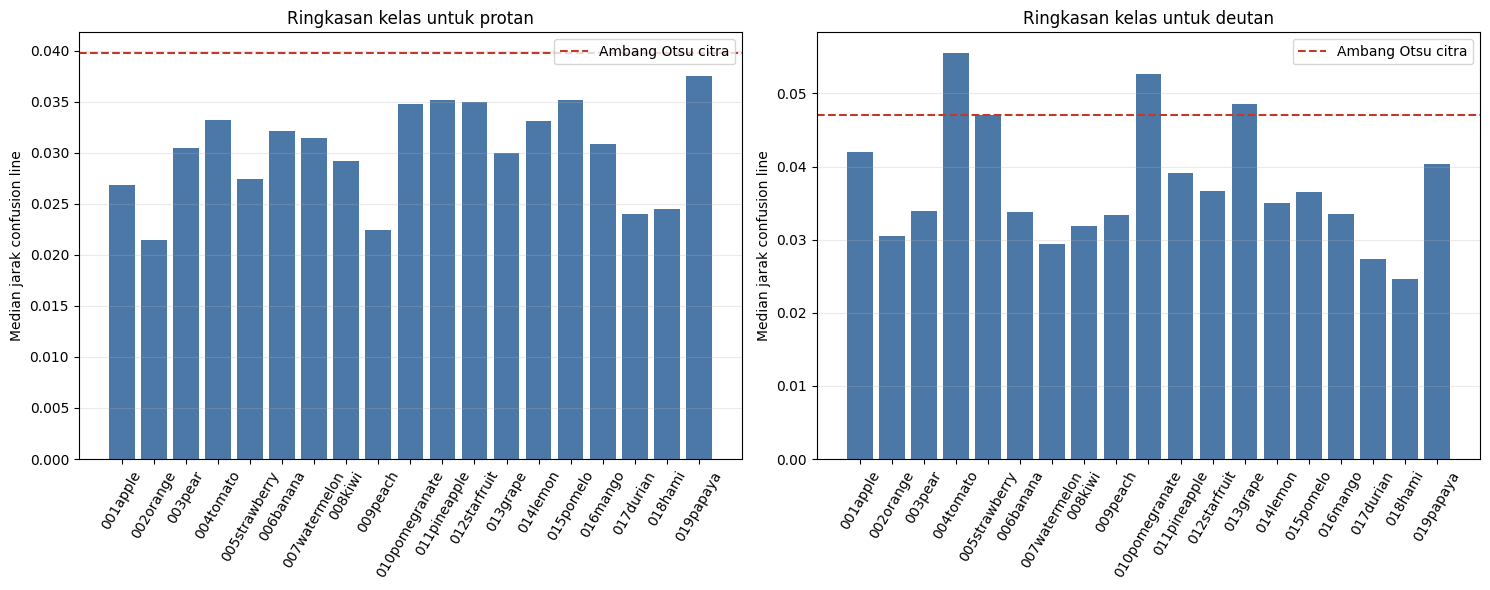

Protan images: 525
Deutan images: 525


In [8]:
required_analysis_state = ['manifest', 'class_confusion_summary', 'ambiguity_thresholds', 'selected_rows_by_cvd']
missing_analysis_state = [name for name in required_analysis_state if name not in globals()]
if missing_analysis_state:
    raise RuntimeError(
        "Jalankan semua sel notebook dari atas. Variabel belum tersedia: "
        + ", ".join(missing_analysis_state)
    )

verification_rows = []
for row in manifest.itertuples(index=False):
    image = cv2.imread(row.output_path, cv2.IMREAD_COLOR)
    verification_rows.append({
        "source_class": row.source_class,
        "output_path": row.output_path,
        "readable": image is not None,
        "width": None if image is None else int(image.shape[1]),
        "height": None if image is None else int(image.shape[0]),
    })
verification = pd.DataFrame(verification_rows)
if not verification["readable"].all() or not (
    (verification["width"] == OUTPUT_SIZE) & (verification["height"] == OUTPUT_SIZE)
).all():
    raise RuntimeError("Verifikasi ukuran atau keterbacaan citra gagal.")
print(f"Seluruh {len(verification)} citra manifest berukuran {OUTPUT_SIZE} x {OUTPUT_SIZE} px.")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cvd in zip(axes, COPUNCTAL_POINTS):
    metric = f"{cvd}_pair_distance_median"
    summary_column = f"{cvd}_distance_median_across_images"
    values = class_confusion_summary[summary_column]
    ax.bar(class_confusion_summary["source_class"], values, color="#4C78A8")
    ax.axhline(ambiguity_thresholds[cvd], color="#C0392B", linestyle="--", label="Ambang Otsu citra")
    ax.set_title(f"Ringkasan kelas untuk {cvd}")
    ax.set_ylabel("Median jarak confusion line")
    ax.tick_params(axis="x", rotation=60)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_line_class_summary.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Protan images: {len(selected_rows_by_cvd['protan'])}")
print(f"Deutan images: {len(selected_rows_by_cvd['deutan'])}")
